<a href="https://colab.research.google.com/github/Pradeep-Kumar-Panga/DecodingComplexities/blob/main/GradientVector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Compass That Trains Every AI: The Gradient Vector

**@DecodingComplexities** | [YouTube](https://www.youtube.com/@DecodingComplexities), [Blog](https://www.pradeeppanga.com)

---

In Machine learning, training a model is like finding the lowest point of a mountain, blindfolded. The machine needs to understand which way is down.

If there is only one feature (2D graph, feature on X - axis and Loss on Y - axis), it gets easy, Machine needs to find the slope to understand if it needs to move right or move left to minimize the loss.

But, the real world is never represented on a 2D graph. If we just consider two features, then it becomes a 3D graph and there are infinite directions to consider (360 degrees, not just right or left any more).

This is just the simplest example, GPT-3 contains 175 billion parameters. We cannot visualize how to move in a 175 billion dimensional space.

If we just have one parameter, we calculate the derivative to find the slope (or Gradient) and move towards minimizing the loss. If we have more than one parameters, Partial derivatives is the way to go and store the outcome in a Gradient Vector.

**In this notebook, we build and understand:**

1. **The dimension problem** — why a single derivative breaks in higher dimensions  
2. **Partial derivatives** — freeze everything except one variable; differentiate normally  
3. **The Gradient Vector** — packing all partial derivatives into one compass  
4. **Gradient Descent** — the loop that trains every neural network  
5. **The Learning Rate trap** — what happens when your step size is wrong  
6. **Full 3D visualisation** — the loss surface, the gradient arrow, and the descent path  

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import FancyArrowPatch
from mpl_toolkits.mplot3d.proj3d import proj_transform
import warnings
warnings.filterwarnings('ignore')

print("✓ Setup complete.")


✓ Setup complete.


---
## 1 · The Dimension Problem

> *"The moment you have more than one parameter, one derivative isn't enough."*

In [Previous video](https://youtu.be/jkkCU_skRZ8), we had a single parameter **w** and a 1D loss curve.  
The derivative `dL/dw` gave us the slope — one number, one direction, done.

The moment we add a second parameter — even just a **bias b** — the loss becomes a surface in 3D space.  
"Slope" is no longer a single number. Every direction on that surface has its own rate of change.

The 1D derivative cannot answer the question: **which way is downhill?**

Let's plot 1D Loss Curve and 2D Loss Curve side by side.


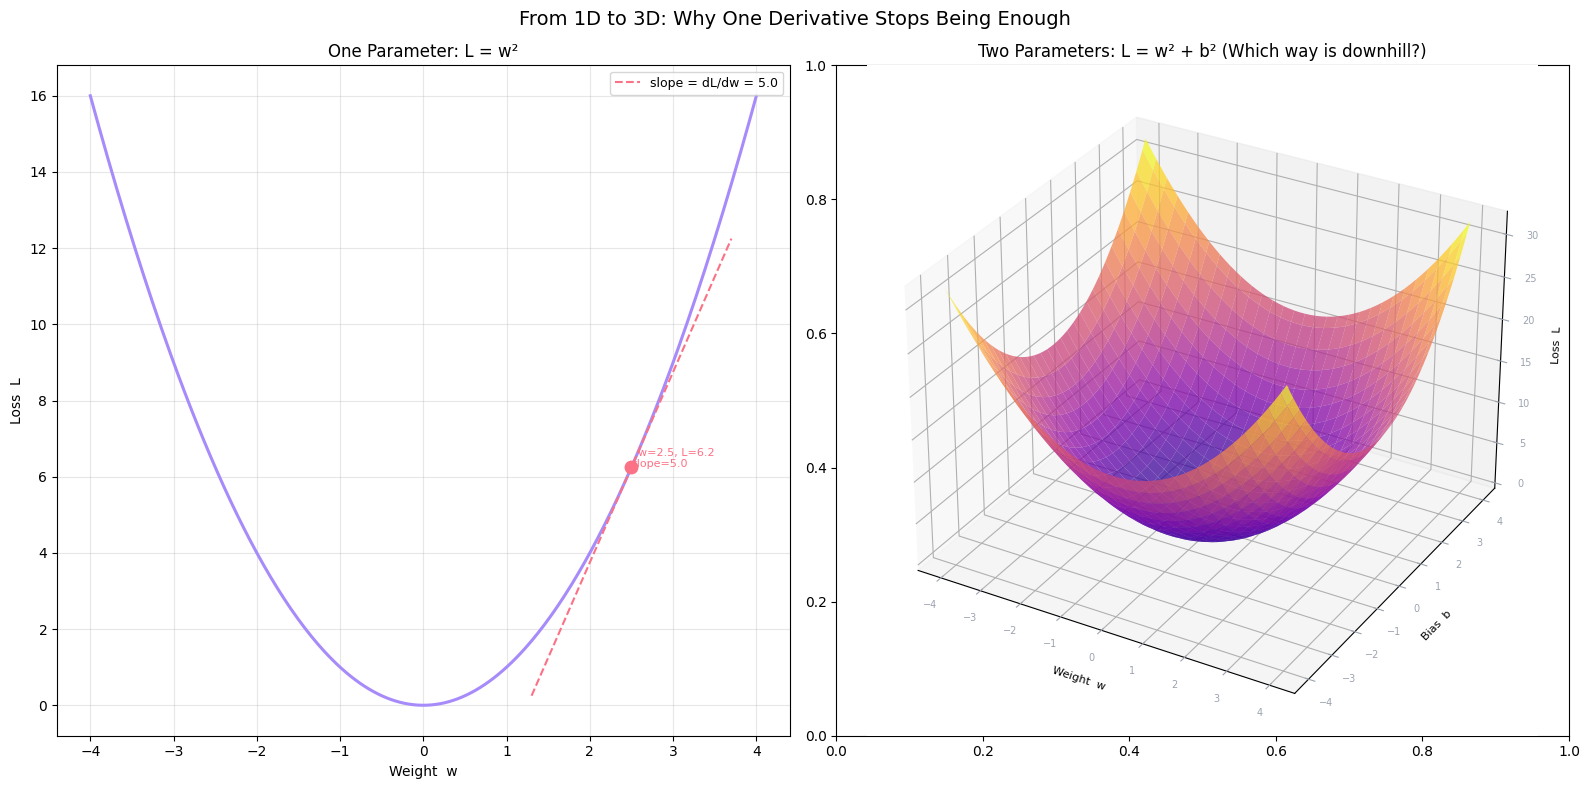

One parameter  → one derivative → one slope. Clear.
Two parameters → infinitely many directions → single derivative fails.

We need a new tool.


In [2]:
# 1D loss curve (one parameter)
w_range = np.linspace(-4, 4, 300)
loss_1d = w_range ** 2 # Loss function is a square of weight i.e., L = w²

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.suptitle("From 1D to 3D: Why One Derivative Stops Being Enough",
             fontsize=14)

# Left: 1D loss curve
ax = axes[0]
ax.plot(w_range, loss_1d, color='#a78bfa', linewidth=2.2)
ax.set_xlabel('Weight  w')
ax.set_ylabel('Loss  L')
ax.set_title('One Parameter: L = w²', fontsize=12)

# Mark a point and its slope
w0 = 2.5
ax.plot(w0, w0**2, 'o', color='#fb7185', markersize=9, zorder=5)
slope = 2 * w0 # Derivative of L = w² is dL/dw = 2w
tangent_x = np.linspace(w0 - 1.2, w0 + 1.2, 50)
tangent_y = w0**2 + slope * (tangent_x - w0)
ax.plot(tangent_x, tangent_y, '--', color='#fb7185', linewidth=1.5, label=f'slope = dL/dw = {slope:.1f}')
ax.annotate(f'  w={w0}, L={w0**2:.1f}\nslope={slope:.1f}',
            xy=(w0, w0**2), fontsize=8, color='#fb7185')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# Right: 3D loss surface — introduction
ax2 = fig.add_subplot(122, projection='3d')
w_vals = np.linspace(-4, 4, 60)
b_vals = np.linspace(-4, 4, 60)
W, B   = np.meshgrid(w_vals, b_vals)
L_surf = W**2 + B**2 # Loss function is a sum of squares of weight and bias i.e., L = w² + b²

ax2.plot_surface(W, B, L_surf, cmap='plasma', alpha=0.75, linewidth=0)
ax2.set_xlabel('Weight  w', fontsize=8)
ax2.set_ylabel('Bias  b',   fontsize=8)
ax2.set_zlabel('Loss  L',   fontsize=8)
ax2.set_title('Two Parameters: L = w² + b² (Which way is downhill?)', fontsize=12)
ax2.tick_params(colors='#9ca3af', labelsize=7)

plt.tight_layout()
plt.show()

print("One parameter  → one derivative → one slope. Clear.")
print("Two parameters → infinitely many directions → single derivative fails.")
print("\nWe need a new tool.")


---
## 2 · Partial Derivatives — Freeze Everything Except One Variable

> *"Freeze the Bias. Lock it in place. Now you have reduced your 3D problem back to a 1D problem."*

**The idea:**  
Instead of computing slope in all directions simultaneously, ask a simpler question one variable at a time:

*What is the slope if I hold every variable constant except this one?*

That operation is the **partial derivative**, written with the curly ∂ symbol.

$$\frac{\partial L}{\partial w} \quad \text{means: treat } b \text{ as a constant, differentiate normally w.r.t. } w$$

For our loss function $L = w^2 + b^2$:

$$\frac{\partial L}{\partial w} = 2w \qquad \frac{\partial L}{\partial b} = 2b$$


In [3]:
# ── Partial derivatives: the freeze-and-differentiate operation ───────────────

def loss(w, b):
    """Our 3D loss function: L = w² + b²
    (a perfect bowl, minimum at origin)"""
    return w**2 + b**2

def partial_w(w):
    """∂L/∂w — slope in the Weight direction
    (Bias frozen)."""
    return 2 * w

def partial_b(b):
    """∂L/∂b — slope in the Bias direction
    (Weight frozen)."""
    return 2 * b

# Standing at w=3, b=4
w0, b0 = 3.0, 4.0
L0     = loss(w0, b0)
dL_dw  = partial_w(w0)
dL_db  = partial_b(b0)

print(f"Position:  w = {w0},  b = {b0}")
print(f"Loss:      L = w² + b² = {L0:.1f}")
print()
print(f"∂L/∂w = 2w = {dL_dw:.1f}   ← slope heading East (along Weight axis)")
print(f"∂L/∂b = 2b = {dL_db:.1f}   ← slope heading North (along Bias axis)")
print()
print("You now have two slopes. One per parameter.")
print("But you are one robot. You can't walk East and North simultaneously.")
print("You need a single direction. → Enter the Gradient Vector.")


Position:  w = 3.0,  b = 4.0
Loss:      L = w² + b² = 25.0

∂L/∂w = 2w = 6.0   ← slope heading East (along Weight axis)
∂L/∂b = 2b = 8.0   ← slope heading North (along Bias axis)

You now have two slopes. One per parameter.
But you are one robot. You can't walk East and North simultaneously.
You need a single direction. → Enter the Gradient Vector.


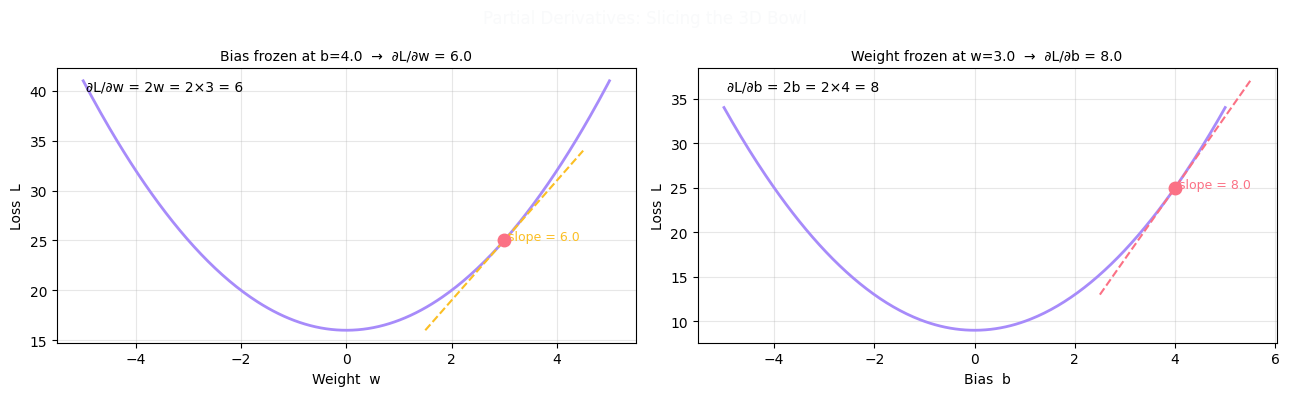

In [4]:
# Visualise: slicing the 3D bowl to show each partial derivative
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("Partial Derivatives: Slicing the 3D Bowl", fontsize=12, color="#f9fafb")

# Left: freeze b, vary w — shows ∂L/∂w
ax = axes[0]
w_slice = np.linspace(-5, 5, 300)
b_fixed = b0
L_w_slice = w_slice**2 + b_fixed**2 # This is the slice of the 3D bowl at b=b0, showing how loss changes as we vary w

ax.plot(w_slice, L_w_slice, color='#a78bfa', linewidth=2)
ax.plot(w0, L0, 'o', color='#fb7185', markersize=9, zorder=5)
slope_w = partial_w(w0)
tang_w  = np.linspace(w0 - 1.5, w0 + 1.5, 50)
tang_Lw = L0 + slope_w * (tang_w - w0)
ax.plot(tang_w, tang_Lw, '--', color='#fbbf24', linewidth=1.5)
ax.set_xlabel('Weight  w')
ax.set_ylabel('Loss  L')
ax.set_title(f'Bias frozen at b={b_fixed:.1f}  →  ∂L/∂w = {slope_w:.1f}', fontsize=10)
ax.annotate(f' slope = {slope_w:.1f}', xy=(w0, L0), fontsize=9, color='#fbbf24')
ax.grid(True, alpha=0.3)
ax.text(0.05, 0.92, f'∂L/∂w = 2w = 2×{w0:.0f} = {slope_w:.0f}',
        transform=ax.transAxes, fontsize=10)

# Right: freeze w, vary b — shows ∂L/∂b
ax2 = axes[1]
b_slice = np.linspace(-5, 5, 300)
w_fixed = w0
L_b_slice = w_fixed**2 + b_slice**2 # This is the slice of the 3D bowl at w=w0, showing how loss changes as we vary b

ax2.plot(b_slice, L_b_slice, color='#a78bfa', linewidth=2)
ax2.plot(b0, L0, 'o', color='#fb7185', markersize=9, zorder=5)
slope_b = partial_b(b0)
tang_b  = np.linspace(b0 - 1.5, b0 + 1.5, 50)
tang_Lb = L0 + slope_b * (tang_b - b0)
ax2.plot(tang_b, tang_Lb, '--', color='#fb7185', linewidth=1.5)
ax2.set_xlabel('Bias  b')
ax2.set_ylabel('Loss  L')
ax2.set_title(f'Weight frozen at w={w_fixed:.1f}  →  ∂L/∂b = {slope_b:.1f}', fontsize=10)
ax2.annotate(f' slope = {slope_b:.1f}', xy=(b0, L0), fontsize=9, color='#fb7185')
ax2.grid(True, alpha=0.3)
ax2.text(0.05, 0.92, f'∂L/∂b = 2b = 2×{b0:.0f} = {slope_b:.0f}',
         transform=ax2.transAxes, fontsize=10)

plt.tight_layout()
plt.show()


---
## 3 · The Gradient Vector — Packing All Partial Derivatives Into One Compass

> *"No matter how many dimensions — 2, 3, or 175 billion — the gradient vector always points in the exact direction of steepest uphill climb."*

**Definition:**

$$\nabla L = \left[\frac{\partial L}{\partial w},\ \frac{\partial L}{\partial b}\right]$$

The upside-down triangle ∇ is called **Nabla**.  
It means: the vector of all partial derivatives of L, one entry per parameter.

**The key property (provable from the chain rule):**  
The gradient vector points in the direction of **maximum rate of increase** of L.  
Flip its sign → direction of maximum rate of **decrease**.  
That is your downhill compass.


In [5]:
# The Gradient Vector
w0, b0 = 3.0, 4.0

gradient = np.array([partial_w(w0), partial_b(b0)])

print("=" * 45)
print("  The Gradient Vector at (w=3, b=4)")
print("=" * 45)
print(f"  ∂L/∂w = {partial_w(w0):.1f}   (slope in Weight direction)")
print(f"  ∂L/∂b = {partial_b(b0):.1f}   (slope in Bias direction)")
print()
print(f"  ∇L = [{gradient[0]:.1f}, {gradient[1]:.1f}]")
print()
print(f"  Magnitude  ‖∇L‖ = {np.linalg.norm(gradient):.4f}")
print(f"  Direction (unit vector) = [{gradient[0]/np.linalg.norm(gradient):.4f}, "
      f"{gradient[1]/np.linalg.norm(gradient):.4f}]")
print()
print(f"  -∇L = [{-gradient[0]:.1f}, {-gradient[1]:.1f}]   ← points DOWNHILL")
print()
print("One vector. Any number of dimensions. Always points uphill.")
print("Negate it → always points downhill. That is all we need.")


  The Gradient Vector at (w=3, b=4)
  ∂L/∂w = 6.0   (slope in Weight direction)
  ∂L/∂b = 8.0   (slope in Bias direction)

  ∇L = [6.0, 8.0]

  Magnitude  ‖∇L‖ = 10.0000
  Direction (unit vector) = [0.6000, 0.8000]

  -∇L = [-6.0, -8.0]   ← points DOWNHILL

One vector. Any number of dimensions. Always points uphill.
Negate it → always points downhill. That is all we need.


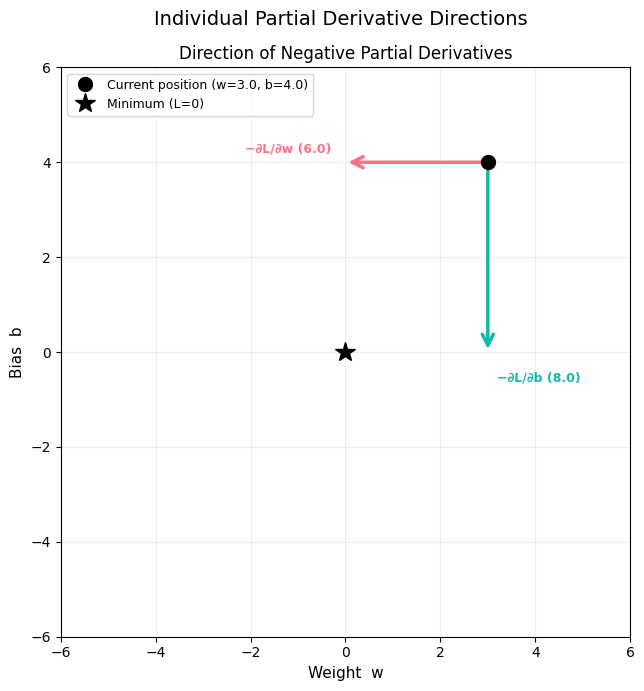

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
fig.suptitle("Individual Partial Derivative Directions", fontsize=14)

# Current position (w=3, b=4) defined in a previous cell
w_current, b_current = w0, b0 # Reusing w0, b0 from previous cells
L_current = loss(w_current, b_current)

# Calculate partial derivatives at the current position
dL_dw_val = partial_w(w_current)
dL_db_val = partial_b(b_current)

ax.plot(w_current, b_current, 'o', color='black', markersize=10, zorder=6, label=f'Current position (w={w_current}, b={b_current})')

# Scaling factor for arrow length to make it visible
scale = 0.5

# Arrow for partial_w (along the w-axis, keeping b constant)
ax.annotate('', xy=(w_current - dL_dw_val * scale, b_current),
            xytext=(w_current, b_current),
            arrowprops=dict(arrowstyle='->', color='#fb7185', lw=2.5, mutation_scale=20))
ax.text(w_current - dL_dw_val * scale * 1.1, b_current + 0.2, f'−∂L/∂w ({dL_dw_val:.1f})', color='#fb7185', fontsize=9, fontweight='bold', ha='right')

# Arrow for partial_b (along the b-axis, keeping w constant)
ax.annotate('', xy=(w_current, b_current - dL_db_val * scale),
            xytext=(w_current, b_current),
            arrowprops=dict(arrowstyle='->', color='#14b8a6', lw=2.5, mutation_scale=20))
ax.text(w_current + 0.2, b_current - dL_db_val * scale * 1.1, f'−∂L/∂b ({dL_db_val:.1f})', color='#14b8a6', fontsize=9, fontweight='bold', va='top')

# Minimum point
ax.plot(0, 0, '*', color='black', markersize=15, zorder=7, label='Minimum (L=0)')

ax.set_xlabel('Weight  w', fontsize=11)
ax.set_ylabel('Bias  b', fontsize=11)
ax.set_title('Direction of Negative Partial Derivatives', fontsize=12)
ax.set_xlim(-6, 6)
ax.set_ylim(-6, 6)
ax.set_aspect('equal')
ax.legend(fontsize=9, loc='upper left')
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

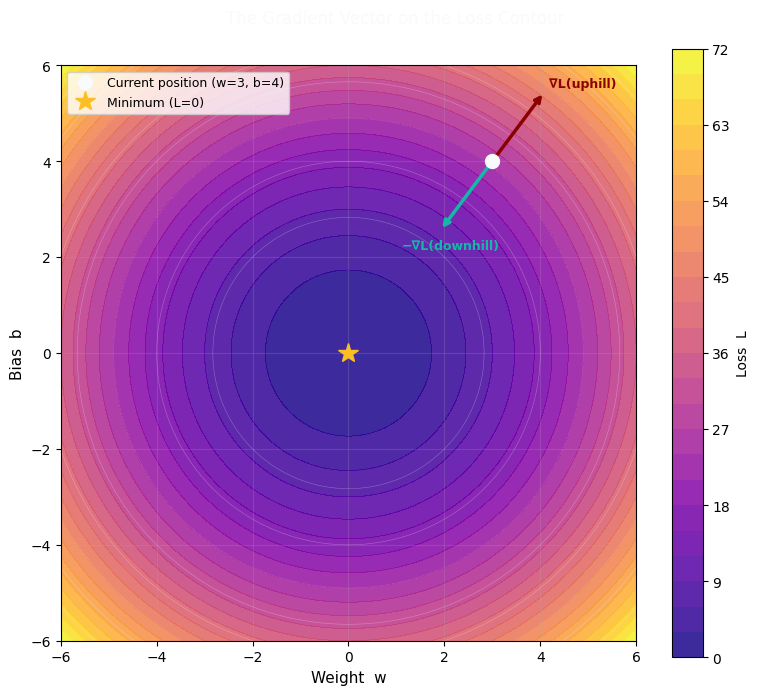

Red arrow  = ∇L   → steepest uphill direction
Green arrow = −∇L  → steepest downhill direction

The green arrow is your compass. Follow it.


In [7]:
# ── Visualise: gradient arrow on the 2D loss contour ─
fig, ax = plt.subplots(figsize=(8, 7))
fig.suptitle("The Gradient Vector on the Loss Contour", fontsize=12, color="#f9fafb")

w_vals = np.linspace(-6, 6, 300)
b_vals = np.linspace(-6, 6, 300)
W, B   = np.meshgrid(w_vals, b_vals)
L_cont = W**2 + B**2

# Contour plot (top-down view of the bowl)
contours = ax.contourf(W, B, L_cont, levels=25, cmap='plasma', alpha=0.85)
ax.contour( W, B, L_cont, levels=10, colors='white', linewidths=0.4, alpha=0.3)
plt.colorbar(contours, ax=ax, label='Loss  L')

# Current position (3, 4)
ax.plot(w0, b0, 'o', color='#f9fafb', markersize=10, zorder=6, label='Current position (w=3, b=4)')

# Gradient arrow (uphill — red)
scale = 0.18 # Just a visual scaling factor to make the arrow fit nicely on the plot
ax.annotate('', xy=(w0 + gradient[0]*scale, b0 + gradient[1]*scale),
            xytext=(w0, b0),
            arrowprops=dict(arrowstyle='->', color='darkred', lw=2.5))
ax.text(w0 + gradient[0]*scale + 0.1, b0 + gradient[1]*scale + 0.1,
        '∇L(uphill)', color='darkred', fontsize=9, fontweight='bold')

# Negative gradient arrow (downhill — green)
ax.annotate('', xy=(w0 - gradient[0]*scale, b0 - gradient[1]*scale),
            xytext=(w0, b0),
            arrowprops=dict(arrowstyle='->', color='#14b8a6', lw=2.5))
ax.text(w0 - gradient[0]*scale - 0.8, b0 - gradient[1]*scale - 0.4,
        '−∇L(downhill)', color='#14b8a6', fontsize=9, fontweight='bold')

# Minimum
ax.plot(0, 0, '*', color='#fbbf24', markersize=15, zorder=7, label='Minimum (L=0)')

ax.set_xlabel('Weight  w', fontsize=11)
ax.set_ylabel('Bias  b', fontsize=11)
ax.set_xlim(-6, 6)
ax.set_ylim(-6, 6)
ax.set_aspect('equal')
ax.legend(fontsize=9, loc='upper left')
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

print("Red arrow  = ∇L   → steepest uphill direction")
print("Green arrow = −∇L  → steepest downhill direction")
print("\nThe green arrow is your compass. Follow it.")


---
## 4 · Gradient Descent — The Loop That Trains Every Neural Network

> *"Compute the gradient. Step opposite to it. Repeat. That loop is Gradient Descent."*

**The update rule:**

$$w_{t+1} = w_t - \alpha \cdot \frac{\partial L}{\partial w} \qquad b_{t+1} = b_t - \alpha \cdot \frac{\partial L}{\partial b}$$

Or in vector form:

$$\theta_{t+1} = \theta_t - \alpha \cdot \nabla L(\theta_t)$$

Where **α** (alpha) is the **Learning Rate** — how large each step is.

This single loop, applied millions of times, is what trains every neural network in existence.


In [8]:
# Clean gradient descent — correct learning rate
def gradient_descent(w_init, b_init, lr, n_steps):
    """Run gradient descent on L = w² + b² and return the full trajectory."""
    w, b = w_init, b_init
    history = {'w': [w], 'b': [b], 'loss': [loss(w, b)], 'grad_norm': []}

    for step in range(n_steps):
        gw = partial_w(w)
        gb = partial_b(b)
        history['grad_norm'].append(np.sqrt(gw**2 + gb**2))
        w = w - lr * gw
        b = b - lr * gb
        history['w'].append(w)
        history['b'].append(b)
        history['loss'].append(loss(w, b))

    return history

# Run with a healthy learning rate
history_good = gradient_descent(w_init=3.0, b_init=4.0, lr=0.1, n_steps=30)

# Print step-by-step
print(f"{'Step':>5}  {'w':>9}  {'b':>9}  {'Loss':>10}  {'‖∇L‖':>10}")
print("─" * 52)
for i in range(0, 31, 5):
    gn = history_good['grad_norm'][i] if i < len(history_good['grad_norm']) else 0.0
    print(f"{i:>5}  {history_good['w'][i]:>9.5f}  {history_good['b'][i]:>9.5f}  "
          f"{history_good['loss'][i]:>10.6f}  {gn:>10.6f}")

print(f"\nFinal loss after 30 steps: {history_good['loss'][-1]:.2e}")
print("Converging cleanly to zero. ✓")


 Step          w          b        Loss        ‖∇L‖
────────────────────────────────────────────────────
    0    3.00000    4.00000   25.000000   10.000000
    5    0.98304    1.31072    2.684355    3.276800
   10    0.32212    0.42950    0.288230    1.073742
   15    0.10555    0.14074    0.030949    0.351844
   20    0.03459    0.04612    0.003323    0.115292
   25    0.01133    0.01511    0.000357    0.037779
   30    0.00371    0.00495    0.000038    0.000000

Final loss after 30 steps: 3.83e-05
Converging cleanly to zero. ✓


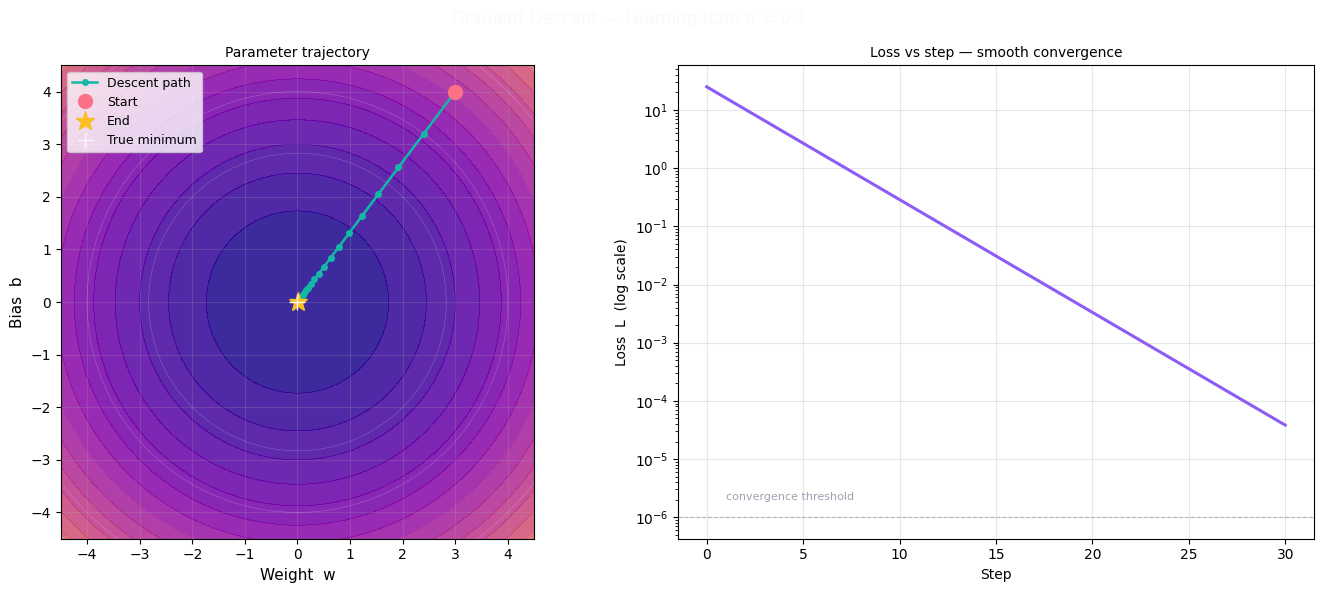

In [9]:
#  Visualise: descent path on the loss contour and loss curve over steps
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Gradient Descent — Learning Rate α = 0.1", fontsize=12, color="#f9fafb")

# Left: trajectory on contour
ax = axes[0]
contours = ax.contourf(W, B, L_cont, levels=25, cmap='plasma', alpha=0.85)
ax.contour( W, B, L_cont, levels=10, colors='white', linewidths=0.4, alpha=0.25)

w_path = history_good['w']
b_path = history_good['b']
ax.plot(w_path, b_path, 'o-', color="#14b8a6", markersize=4, linewidth=1.8,
        label='Descent path', zorder=5)
ax.plot(w_path[0],  b_path[0],  'o', color="#fb7185", markersize=10, zorder=6, label='Start')
ax.plot(w_path[-1], b_path[-1], '*', color="#fbbf24",  markersize=14, zorder=7, label='End')
ax.plot(0, 0, '+', color="#f9fafb", markersize=12, zorder=8, label='True minimum')

ax.set_xlabel('Weight  w', fontsize=11)
ax.set_ylabel('Bias  b',   fontsize=11)
ax.set_title('Parameter trajectory', fontsize=10)
ax.set_xlim(-4.5, 4.5)
ax.set_ylim(-4.5, 4.5)
ax.set_aspect('equal')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.2)

# Right: loss curve over steps
ax2 = axes[1]
steps = np.arange(len(history_good['loss']))
ax2.semilogy(steps, history_good['loss'], color="#8b5cf6", linewidth=2.2)
ax2.set_xlabel('Step')
ax2.set_ylabel('Loss  L  (log scale)')
ax2.set_title('Loss vs step — smooth convergence', fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.axhline(1e-6, color="#9ca3af", linewidth=0.8, linestyle='--', alpha=0.7)
ax2.text(1, 2e-6, 'convergence threshold', fontsize=8, color="#9ca3af")

plt.tight_layout()
plt.show()


---
## 5 · The Learning Rate Trap — What Happens When Your Step Size Is Wrong

> *"If your step size is too large, you overshoot the minimum entirely. The loss doesn't decrease. It explodes."*

The gradient tells you **which direction** to step.  
The learning rate α tells you **how far**.

Too large → overshoot → bounce up the other side → diverge → NaN  
Too small → barely move → training takes forever → often gets stuck in flat regions

This is one of the most consequential decisions in training any neural network.  
The plots below show all three regimes side by side.


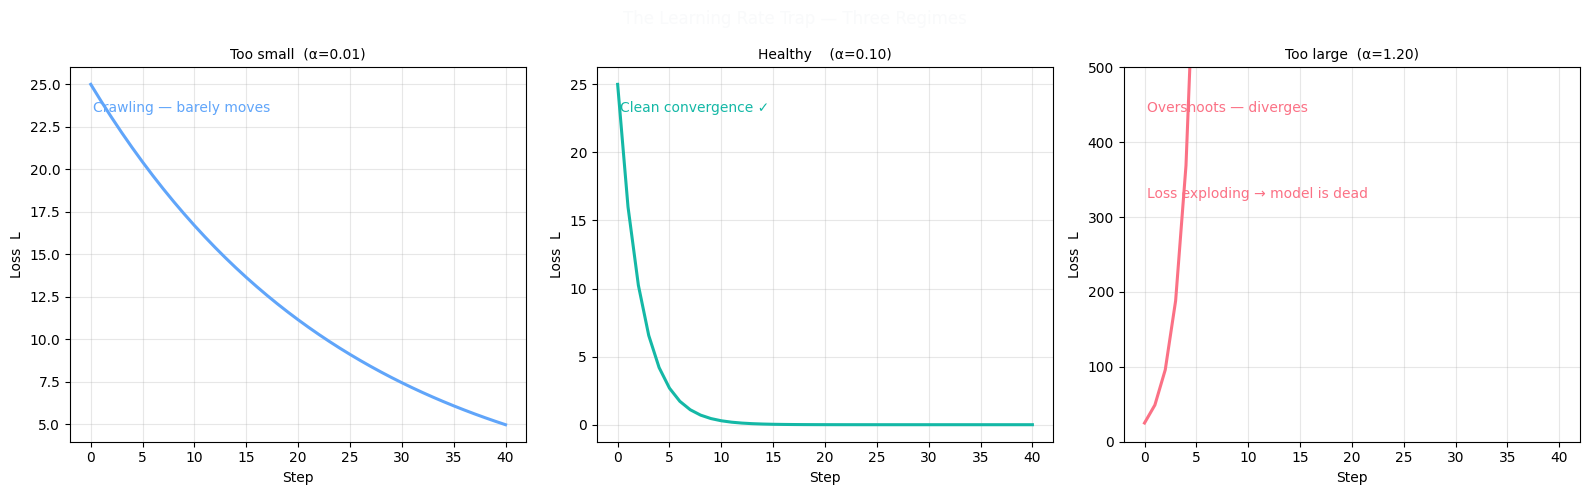

α too small:  model crawls. May never converge in reasonable time.
α healthy:    smooth descent. This is what you want.
α too large:  loss explodes. In real training, this prints NaN.


In [10]:
# Three learning rate regimes
configs = [
    (0.01,  'Too small  (α=0.01)',  "#60a5fa",   'Crawling — barely moves'),
    (0.10,  'Healthy    (α=0.10)',  "#14b8a6",   'Clean convergence ✓'),
    (1.20,  'Too large  (α=1.20)',  "#fb7185",  'Overshoots — diverges'),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("The Learning Rate Trap — Three Regimes", fontsize=12, color="#f9fafb")

for ax, (lr, label, color, note) in zip(axes, configs):
    hist = gradient_descent(3.0, 4.0, lr=lr, n_steps=40)
    losses = hist['loss']

    # Clip for display
    losses_display = [min(l, 1e4) for l in losses]

    ax.plot(losses_display, color=color, linewidth=2.2)
    ax.set_xlabel('Step')
    ax.set_ylabel('Loss  L')
    ax.set_title(label, fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.text(0.05, 0.88, note, transform=ax.transAxes,
            fontsize=10, color=color)

    if lr > 1.0:
        ax.set_ylim(0, min(max(losses_display) * 1.1, 500))
        ax.text(0.05, 0.65, 'Loss exploding → model is dead',
                transform=ax.transAxes, fontsize=10, color="#fb7185")

plt.tight_layout()
plt.show()

print("α too small:  model crawls. May never converge in reasonable time.")
print("α healthy:    smooth descent. This is what you want.")
print("α too large:  loss explodes. In real training, this prints NaN.")


In [11]:
# Step-by-step: what overshoot looks like numerically
print("Learning Rate = 1.2  (too large)")
print()
print(f"{'Step':>5}  {'w':>10}  {'b':>10}  {'Loss':>12}")
print("─" * 46)

w, b = 3.0, 4.0
lr_bad = 1.2
for step in range(10):
    L = loss(w, b)
    print(f"{step:>5}  {w:>10.4f}  {b:>10.4f}  {L:>12.4f}")
    if L > 1e6:
        print("       *** Loss has exploded. Model is dead. ***")
        break
    gw = partial_w(w)
    gb = partial_b(b)
    w  = w - lr_bad * gw
    b  = b - lr_bad * gb

print()
print("Notice: instead of decreasing, loss is growing at each step.")
print("The gradient is correct. The step size is killing it.")


Learning Rate = 1.2  (too large)

 Step           w           b          Loss
──────────────────────────────────────────────
    0      3.0000      4.0000       25.0000
    1     -4.2000     -5.6000       49.0000
    2      5.8800      7.8400       96.0400
    3     -8.2320    -10.9760      188.2384
    4     11.5248     15.3664      368.9473
    5    -16.1347    -21.5130      723.1366
    6     22.5886     30.1181     1417.3478
    7    -31.6241    -42.1654     2778.0017
    8     44.2737     59.0316     5444.8833
    9    -61.9831    -82.6442    10671.9714

Notice: instead of decreasing, loss is growing at each step.
The gradient is correct. The step size is killing it.


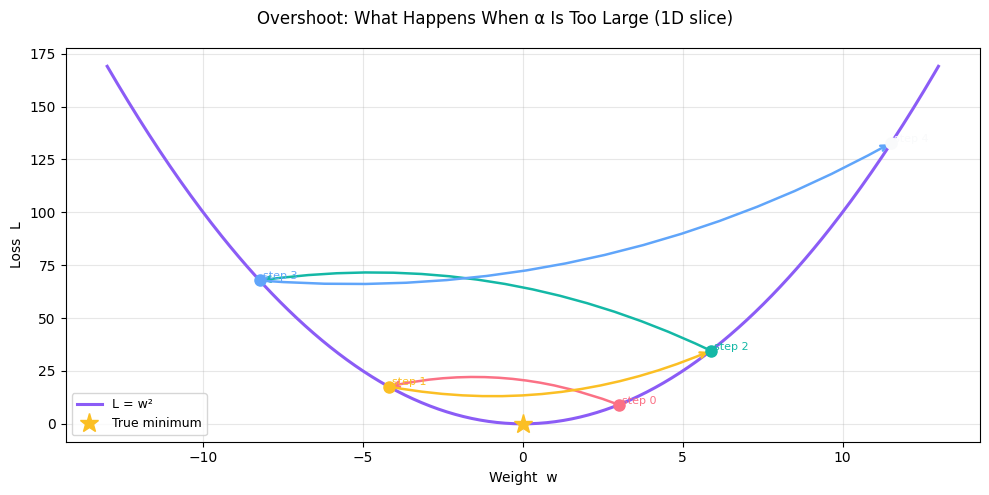

Each step overshoots the minimum and lands higher on the other side.
The model bounces back and forth, never converging.

The fix: control the step size. That is the Learning Rate.
How to choose it correctly → Episode 3.


In [12]:
# Overshoot visualised on the 1D slice (b=0 slice of the bowl)
fig, ax = plt.subplots(figsize=(10, 5))
fig.suptitle("Overshoot: What Happens When α Is Too Large (1D slice)",
             fontsize=12)

w_range_plot = np.linspace(-13, 13, 400)
ax.plot(w_range_plot, w_range_plot**2, color="#8b5cf6", linewidth=2.2, label='L = w²')
ax.set_xlabel('Weight  w')
ax.set_ylabel('Loss  L')
ax.grid(True, alpha=0.3)

# Simulate overshoot on 1D (b=0 slice)
w_os = 3.0
lr_os = 1.2
colors_path = ["#fb7185", "#fbbf24", "#14b8a6", "#60a5fa", "#f9fafb"]

for i in range(5):
    L_os = w_os ** 2
    gw_os = 2 * w_os
    w_next = w_os - lr_os * gw_os

    ax.annotate('', xy=(w_next, w_next**2), xytext=(w_os, L_os),
                arrowprops=dict(arrowstyle='->', color=colors_path[i % len(colors_path)],
                                lw=1.8, connectionstyle='arc3,rad=0.15'))
    ax.plot(w_os, L_os, 'o', color=colors_path[i % len(colors_path)],
            markersize=8, zorder=6)
    ax.text(w_os + 0.1, L_os + 0.5, f'step {i}', fontsize=8,
            color=colors_path[i % len(colors_path)])
    w_os = w_next

ax.plot(0, 0, '*', color="#fbbf24", markersize=14, zorder=7, label='True minimum')
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

print("Each step overshoots the minimum and lands higher on the other side.")
print("The model bounces back and forth, never converging.")
print("\nThe fix: control the step size. That is the Learning Rate.")
print("How to choose it correctly → Episode 3.")


---
## 6 · Full 3D Visualisation — Loss Surface, Gradient Arrow, and Descent Path

> *"When you see a training loss curve drop smoothly toward zero, this is what is happening underneath."*

The full picture: the 3D bowl, the gradient arrow at our starting position,  
and the complete descent path traced from start to minimum.


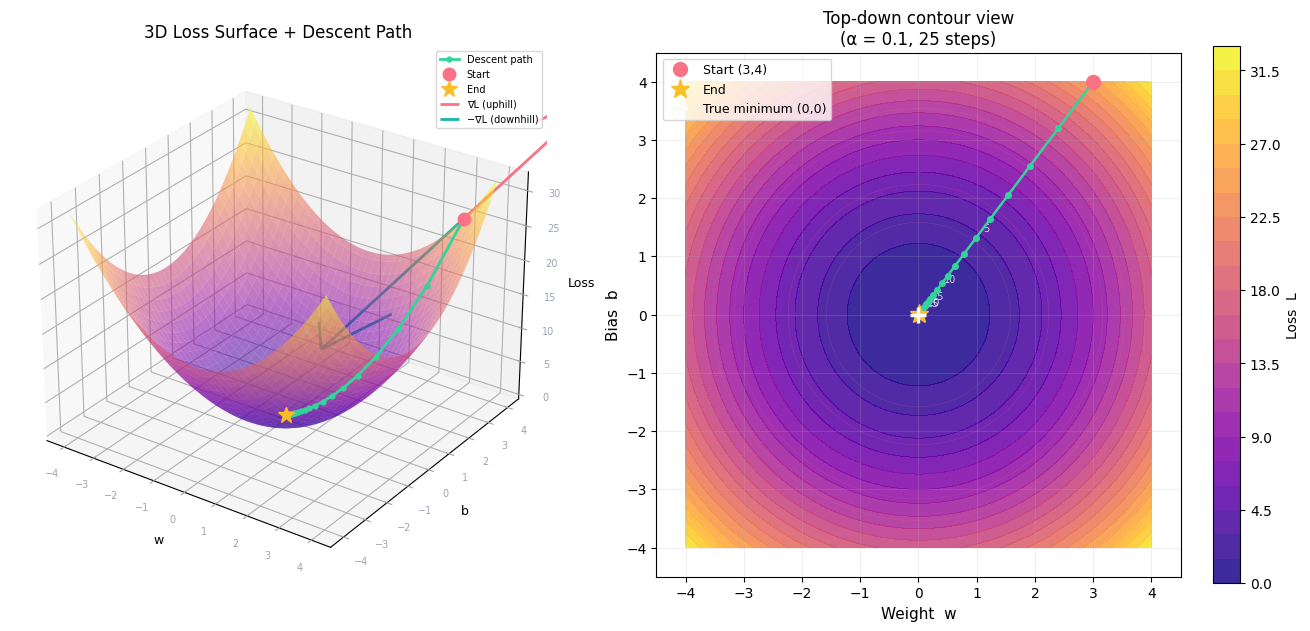

This is gradient descent. Every step follows −∇L.
After 25 steps from (3, 4), loss has dropped from 25.0 to near zero.

  Start: w=3.0,  b=4.0,  L=25.0000
  End:   w=0.0113,  b=0.0151,  L=3.57e-04


In [13]:
# 3D surface with gradient arrow and descent path
fig = plt.figure(figsize=(14, 6))

# Left: 3D surface + descent path
ax3d = fig.add_subplot(121, projection='3d')

w_plot = np.linspace(-4, 4, 80)
b_plot = np.linspace(-4, 4, 80)
Wp, Bp = np.meshgrid(w_plot, b_plot)
Lp     = Wp**2 + Bp**2

ax3d.plot_surface(Wp, Bp, Lp, cmap='plasma', alpha=0.55, linewidth=0,
                  antialiased=True)

# Descent path
hist = gradient_descent(3.0, 4.0, lr=0.1, n_steps=25)
wp   = np.array(hist['w'])
bp   = np.array(hist['b'])
lp   = np.array(hist['loss'])

ax3d.plot(wp, bp, lp, 'o-', color="#34d399", markersize=3.5, linewidth=2,
          zorder=10, label='Descent path')
ax3d.plot([wp[0]],  [bp[0]],  [lp[0]],  'o', color="#fb7185",  markersize=9,
          zorder=11, label='Start')
ax3d.plot([wp[-1]], [bp[-1]], [lp[-1]], '*', color="#fbbf24",  markersize=12,
          zorder=12, label='End')

# Gradient arrow at start
w_s, b_s = wp[0], bp[0]
gw_s = partial_w(w_s) * 0.4
gb_s = partial_b(b_s) * 0.4
gL_s = (2 * w_s * gw_s + 2 * b_s * gb_s) * 0.4
ax3d.quiver(w_s, b_s, lp[0], gw_s, gb_s, gL_s,
            color="#fb7185", linewidth=2, arrow_length_ratio=0.25, label='∇L (uphill)')
ax3d.quiver(w_s, b_s, lp[0], -gw_s, -gb_s, -gL_s,
            color="#14b8a6", linewidth=2, arrow_length_ratio=0.25, label='−∇L (downhill)')

ax3d.set_xlabel('w', fontsize=9)
ax3d.set_ylabel('b', fontsize=9)
ax3d.set_zlabel('Loss', fontsize=9)
ax3d.set_title('3D Loss Surface + Descent Path', fontsize=12)
ax3d.tick_params(colors="#9ca3af", labelsize=7)
ax3d.legend(fontsize=7, loc='upper right')
ax3d.view_init(elev=28, azim=-55)

# Right: 2D contour + path
ax2d = fig.add_subplot(122)

cf = ax2d.contourf(Wp, Bp, Lp, levels=30, cmap='plasma', alpha=0.85)
ax2d.contour( Wp, Bp, Lp, levels=12, colors='#fb7185', linewidths=0.3, alpha=0.3)
plt.colorbar(cf, ax=ax2d, label='Loss  L')

ax2d.plot(wp, bp, 'o-', color="#34d399", markersize=4, linewidth=1.8, zorder=5)
ax2d.plot(wp[0],  bp[0],  'o', color="#fb7185", markersize=10, zorder=6, label='Start (3,4)')
ax2d.plot(wp[-1], bp[-1], '*', color="#fbbf24",  markersize=14, zorder=7, label='End')
ax2d.plot(0, 0, '+', color="#f9fafb", markersize=12, markeredgewidth=2.5,
          zorder=8, label='True minimum (0,0)')

ax2d.set_xlabel('Weight  w', fontsize=11)
ax2d.set_ylabel('Bias  b',   fontsize=11)
ax2d.set_title('Top-down contour view\n(α = 0.1, 25 steps)', fontsize=12)
ax2d.set_xlim(-4.5, 4.5)
ax2d.set_ylim(-4.5, 4.5)
ax2d.set_aspect('equal')
ax2d.legend(fontsize=9)
ax2d.grid(True, alpha=0.2)

# Step number labels every 5 steps
for i in range(0, len(wp), 5):
    ax2d.text(wp[i] + 0.12, bp[i] + 0.12, str(i), fontsize=7, color="#f9fafb", alpha=0.8)

plt.tight_layout()
plt.show()

print("This is gradient descent. Every step follows −∇L.")
print("After 25 steps from (3, 4), loss has dropped from 25.0 to near zero.")
print()
print(f"  Start: w={wp[0]:.1f},  b={bp[0]:.1f},  L={lp[0]:.4f}")
print(f"  End:   w={wp[-1]:.4f},  b={bp[-1]:.4f},  L={lp[-1]:.2e}")


---
## 7 · Scaling to N Dimensions — Why the Gradient Still Works

> *"175 billion parameters. One gradient vector. Same mathematics."*

For a model with N parameters $\theta = [\theta_1, \theta_2, ..., \theta_N]$:

$$\nabla L(\theta) = \left[\frac{\partial L}{\partial \theta_1},\ \frac{\partial L}{\partial \theta_2},\ ...,\ \frac{\partial L}{\partial \theta_N}\right]$$

The update rule is identical regardless of N:

$$\theta_{t+1} = \theta_t - \alpha \cdot \nabla L(\theta_t)$$

The computation scales — via backpropagation — but the mathematics is exactly what we've derived here.  
Below we verify this on a toy N-dimensional loss.


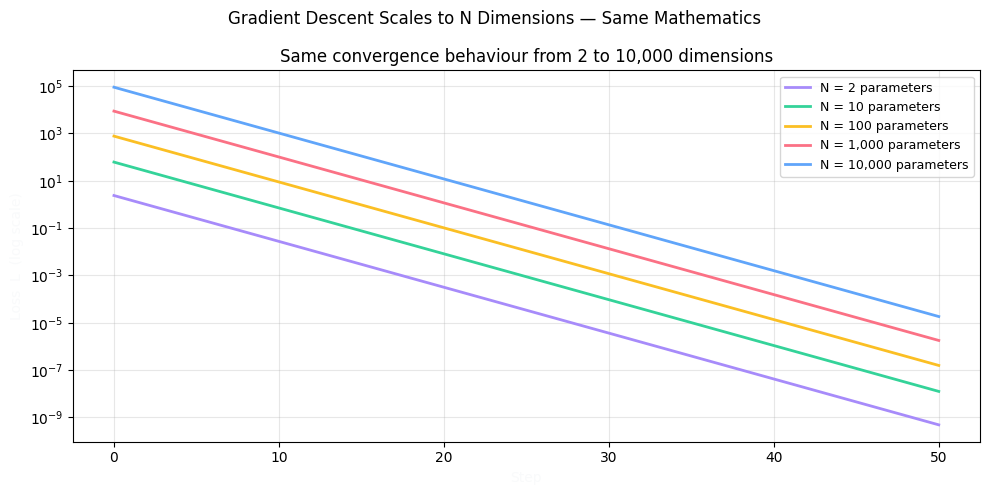

Identical convergence rate regardless of N.
The gradient vector works in 2 dimensions and in 175 billion dimensions.
The update rule is the same. The math is the same.
Only the compute required to evaluate the gradient changes — that is backpropagation.

Backpropagation → Episode 4.


In [14]:
# Gradient descent in N dimensions
# Loss: L(θ) = sum of θᵢ² — a generalised bowl in N dimensions
# ∂L/∂θᵢ = 2θᵢ  for all i

def loss_nd(theta):
    return np.sum(theta**2)

def gradient_nd(theta):
    return 2 * theta          # vector of partial derivatives

def gd_nd(theta_init, lr=0.1, n_steps=40):
    theta = theta_init.copy()
    losses = [loss_nd(theta)]
    for _ in range(n_steps):
        grad  = gradient_nd(theta)
        theta = theta - lr * grad
        losses.append(loss_nd(theta))
    return theta, losses

# Run for several values of N
fig, ax = plt.subplots(figsize=(10, 5))
fig.suptitle("Gradient Descent Scales to N Dimensions — Same Mathematics",
             fontsize=12)

colors_nd = ["#a78bfa", "#34d399", "#fbbf24", "#fb7185", "#60a5fa"]
np.random.seed(42)

for N, color in zip([2, 10, 100, 1000, 10000], colors_nd):
    theta_init = np.random.randn(N) * 3
    _, losses  = gd_nd(theta_init, lr=0.1, n_steps=50)
    ax.semilogy(losses, color=color, linewidth=2, label=f'N = {N:,} parameters')

ax.set_xlabel('Step', color="#f9fafb")
ax.set_ylabel('Loss  L  (log scale)', color="#f9fafb")
ax.set_title('Same convergence behaviour from 2 to 10,000 dimensions', fontsize=12)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Identical convergence rate regardless of N.")
print("The gradient vector works in 2 dimensions and in 175 billion dimensions.")
print("The update rule is the same. The math is the same.")
print("Only the compute required to evaluate the gradient changes — that is backpropagation.")
print("\nBackpropagation → Episode 4.")


---
## 8 · Summary — The Full Arc

| Concept | What it means | Key formula |
|---------|--------------|-------------|
| **Single derivative** | Slope in 1D | `dL/dw` |
| **Partial derivative** | Slope in one direction, all others frozen | `∂L/∂w`, `∂L/∂b` |
| **Gradient vector** | All partial derivatives packed into one array | `∇L = [∂L/∂w, ∂L/∂b, ...]` |
| **Gradient property** | ∇L always points in the direction of steepest ascent | proven from chain rule |
| **Gradient descent** | Step in the −∇L direction, repeat | `θ ← θ − α·∇L` |
| **Learning rate α** | Controls step size — too large explodes, too small crawls | hyperparameter |

---

**The one-sentence version:**  
You can't compute a single slope in high dimensions — so you compute one slope per parameter (partial derivatives), pack them into a vector (the gradient), flip its sign, and take a step. That loop, repeated millions of times, is what trains every AI in existence.

---
